# Phase 6 — Paper Figure Generation

Produces all paper figures (F1–F9 as defined in outline v3) from existing CSV
and NPZ outputs. Each figure is saved as both PDF (vector, for the manuscript)
and PNG (for quick preview).

Output location: `phase6_figures/`. About 30 seconds total.


## 1. Setup

In [2]:
from pathlib import Path
import sys
PROJECT_ROOT = Path('/fs1/home/atikul/Phenology')
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib
matplotlib.use('Agg')   # no display needed; we save to file

from figures import make_all


## 2. Generate all figures

In [3]:
results = make_all(
    data_dir=PROJECT_ROOT,
    output_dir=PROJECT_ROOT / 'phase6_figures',
)
print()
print(results.to_string(index=False))


F1: wrote F1_hgb_streams.pdf and F1_hgb_streams.png
F2: wrote F2_hgb_vs_lstm.pdf and F2_hgb_vs_lstm.png
F3: wrote F3_lstm_phase_heatmap.pdf and F3_lstm_phase_heatmap.png
F4: wrote F4_supervision_winrate.pdf and F4_supervision_winrate.png
F5: wrote F5_attention_heatmap.pdf and F5_attention_heatmap.png


/fs1/home/atikul/Phenology/figures/figures.py:264: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  agg = (errs.groupby(['phase','stream','stratum_pyt'])['ae']


F6: wrote F6_cloud_conditional.pdf and F6_cloud_conditional.png
F9: wrote F9_loyo_stability.pdf and F9_loyo_stability.png

figure status
    F1     ok
    F2     ok
    F3     ok
    F4     ok
    F5     ok
    F6     ok
    F9     ok


## 3. Preview each figure inline


--- F1_hgb_streams.png ---


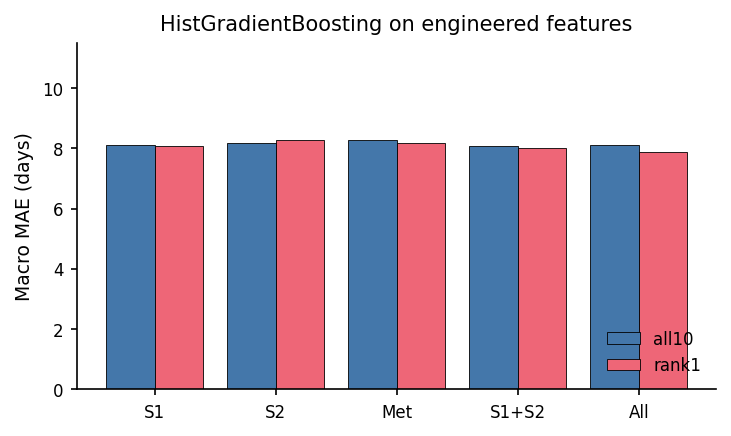


--- F2_hgb_vs_lstm.png ---


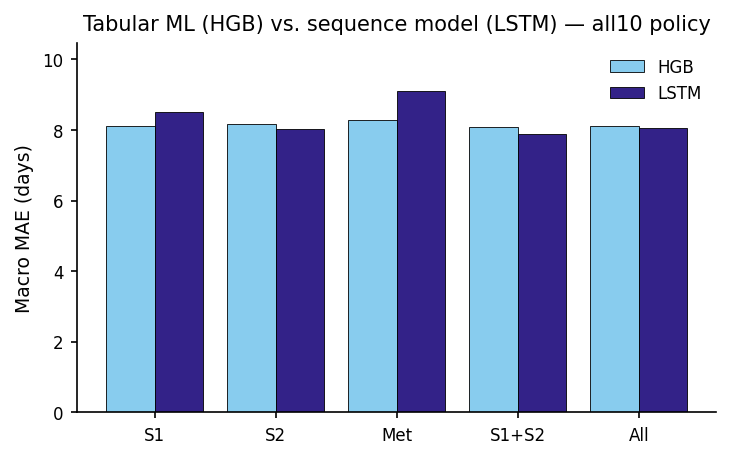


--- F3_lstm_phase_heatmap.png ---


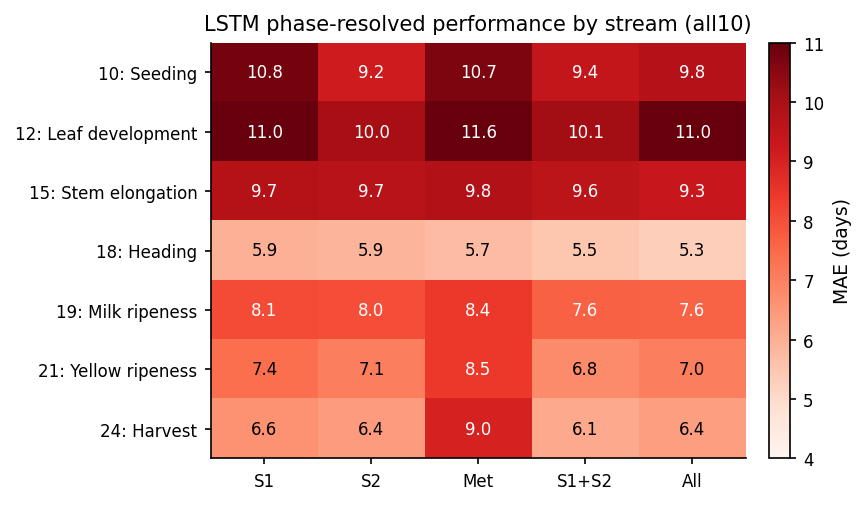


--- F4_supervision_winrate.png ---


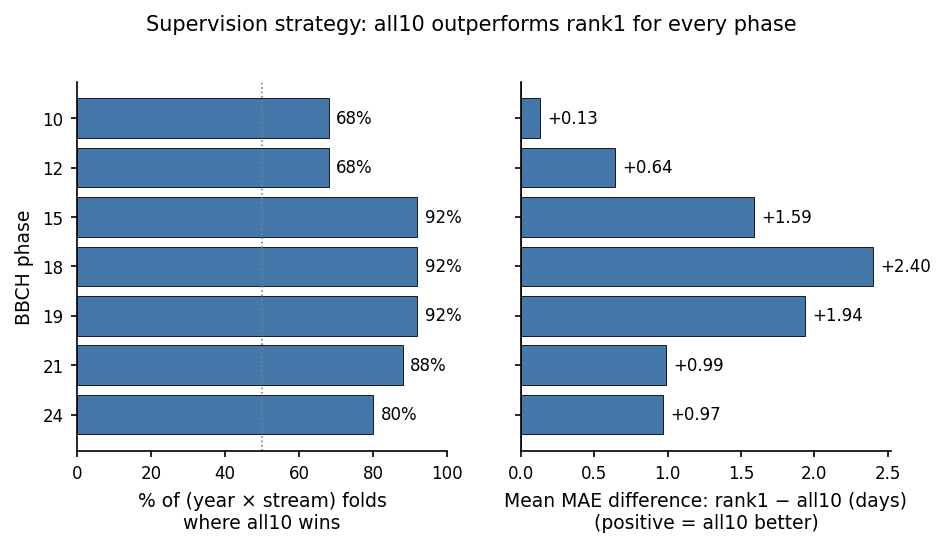


--- F5_attention_heatmap.png ---


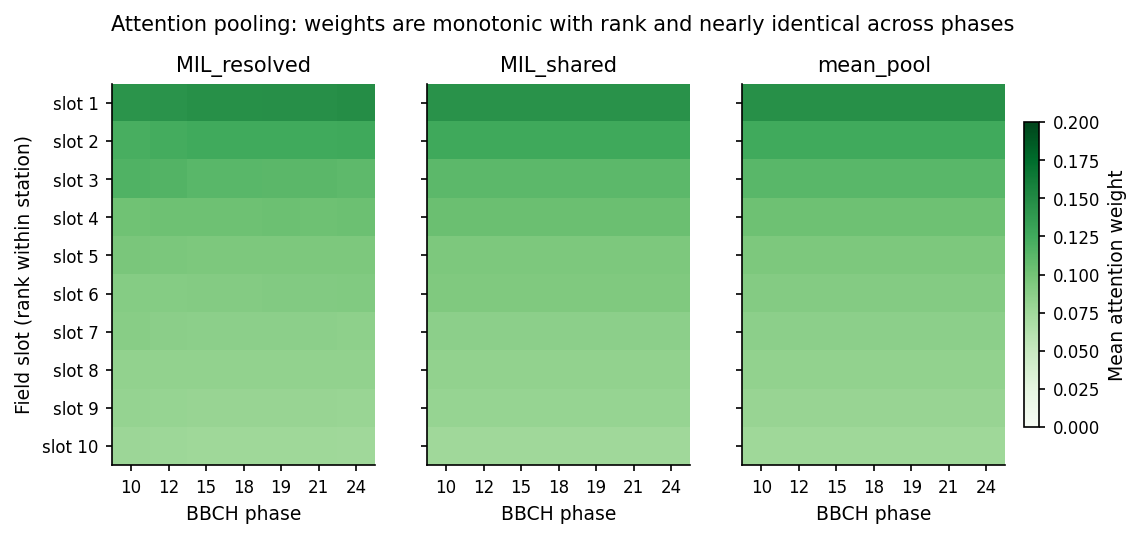


--- F6_cloud_conditional.png ---


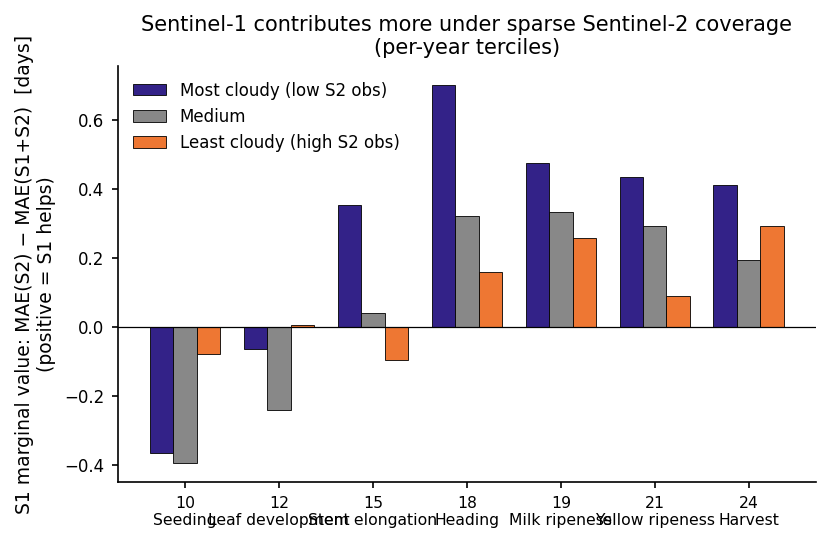


--- F9_loyo_stability.png ---


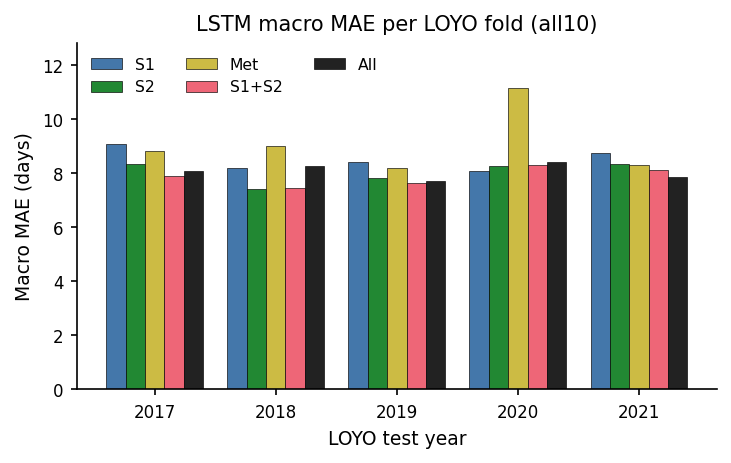

In [4]:
# Show PNGs in the notebook for quick eyeballing
from IPython.display import Image, display
from pathlib import Path

fig_dir = PROJECT_ROOT / 'phase6_figures'
for png in sorted(fig_dir.glob('*.png')):
    print(f'\n--- {png.name} ---')
    display(Image(filename=str(png), width=700))


## 4. Regenerate a single figure if needed

In [5]:
# If you want to tweak one figure quickly without rerunning all of them:
from figures.style import apply_style
from figures.figures import fig6_cloud_conditional   # change to whichever
apply_style()
fig6_cloud_conditional(PROJECT_ROOT, PROJECT_ROOT / 'phase6_figures')


/fs1/home/atikul/Phenology/figures/figures.py:264: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  agg = (errs.groupby(['phase','stream','stratum_pyt'])['ae']


(PosixPath('/fs1/home/atikul/Phenology/phase6_figures/F6_cloud_conditional.pdf'),
 PosixPath('/fs1/home/atikul/Phenology/phase6_figures/F6_cloud_conditional.png'))

## Notes

- **F7 (pipeline schematic) and F8 (example LSTM curves)** are not yet produced
  here. F7 is a manual diagram (best made in Inkscape/PowerPoint, or LaTeX
  TikZ in the manuscript itself). F8 will be a follow-up notebook that picks
  4 representative fields and plots their per-day probability curves vs
  the DWD references — that one is more bespoke and I want to choose the
  fields carefully.

- All PDFs use **embedded TrueType fonts** so they're editable in Illustrator
  if you want to tweak labels post-hoc.

- The colour palette is colourblind-safe (Tol palette).

- If you want to make any figure landscape, taller, narrower, etc., it's a
  single-line change in `figures/figures.py` (the `figsize=` argument).
